# REHAB26-ViewAngles: GPU check and preliminary data exploration

Data: Jánošová, Budikova, & Sedmidubsky (2026), https://doi.org/10.5281/zenodo.23018128.

## 1. GPU access

In [1]:
import torch
print("PyTorch", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

PyTorch 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
VRAM (GB): 12.3


## 2. Setup

In [2]:
import glob, json, os, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

seg = pd.read_csv(DATA / "raw/Segmentation.csv", sep=";")
errs = pd.read_csv(DATA / "raw/Error_types.csv", sep=";")
joint_names = [l.split(": ")[1] for l in (DATA / "raw/joint_names.txt").read_text().strip().splitlines()]
EX_NAME = {1: "Arm abduction", 6: "Squat", 7: "Shoulder extension"}
seg["exercise"] = seg.exercise_id.map(EX_NAME)
seg["label"] = seg.correctness_score.map({1: "correct", 5: "incorrect"})
seg["n_frames"] = seg.last_frame - seg.first_frame + 1
print(seg.shape, "labeled repetitions")
seg.head()

(1665, 14) labeled repetitions


,video_id,exercise_id,exercise_subtype,person,repetition_number,first_frame,last_frame,person_orientation,correctness_score,error_description,additional_errors,exercise,label,n_frames
0,ex1_Honza,1,right,Honza,1,8,158,0,1,NaN,NaN,Arm abduction,correct,151
1,ex1_Honza,1,right,Honza,2,174,306,0,1,NaN,NaN,Arm abduction,correct,133
2,ex1_Honza,1,right,Honza,3,330,471,0,1,NaN,NaN,Arm abduction,correct,142
3,ex1_Honza,1,right,Honza,4,566,728,0,5,ERR_ARM_FORWARD,NaN,Arm abduction,incorrect,163
4,ex1_Honza,1,right,Honza,5,747,950,0,5,ERR_ELEVATED_SHOULDER,NaN,Arm abduction,incorrect,204


## 3. Labels

The target is `correctness_score` (1 = correct, 5 = incorrect). Each incorrect repetition also carries the
intended error code, and occasionally additional errors that the annotators observed.

In [3]:
print("Overall:", seg.label.value_counts().to_dict())
display(pd.crosstab(seg.exercise, seg.label, margins=True))
display(pd.crosstab(seg.person, seg.label, margins=True))
display(pd.crosstab(seg.person_orientation, seg.label).T)

Overall: {'incorrect': 833, 'correct': 832}


label,correct,incorrect,All
exercise,,,
Arm abduction,278,278,556
Shoulder extension,278,277,555
Squat,276,278,554
All,832,833,1665


label,correct,incorrect,All
person,,,
Honza,166,165,331
Mima,166,169,335
Petra,165,166,331
Terka,165,165,330
Vasil,170,168,338
All,832,833,1665


person_orientation,0,10,20,30,40,45,50,60,70,80,90
label,,,,,,,,,,,
correct,80,76,75,75,75,75,76,75,75,75,75
incorrect,76,75,77,75,75,76,75,77,75,77,75


In [4]:
err_counts = (seg.dropna(subset=["error_description"])
              .groupby(["exercise", "error_description"]).size().rename("n").reset_index())
display(err_counts)
print("Repetitions with additional observed errors:", seg.additional_errors.notna().sum())
display(seg.additional_errors.value_counts())

,exercise,error_description,n
0,Arm abduction,ERR_ARM_FORWARD,56
1,Arm abduction,ERR_BENT_ARM,56
2,Arm abduction,ERR_ELEVATED_SHOULDER,55
3,Arm abduction,ERR_HEAD_TO_SIDE,56
4,Arm abduction,ERR_LOW_ABDUCTION,55
5,Shoulder extension,ERR_ARM_TO_SIDE,56
6,Shoulder extension,ERR_BENT_ARM,56
7,Shoulder extension,ERR_ELEVATED_SHOULDER,55
8,Shoulder extension,ERR_TORSO_FORWARD,55
9,Shoulder extension,ERR_TORSO_ROTATION,55


Repetitions with additional observed errors: 34


additional_errors
ERR_ELEVATED_SHOULDER                 17
ERR_TORSO_FORWARD                      6
ERR_BENT_ARM                           3
ERR_HEAD_TO_SIDE,ERR_BENT_ARM          3
ERR_HEAD_TO_SIDE                       3
ERR_ELEVATED_SHOULDER,ERR_BENT_ARM     2
Name: count, dtype: int64

## 4. Repetition length

Repetitions are variable length and must be resampled or padded before batching. Incorrect repetitions
are longer on average, which means duration alone carries label information and models should not be
allowed to exploit it trivially (time-normalising each repetition removes it).

,count,mean,std,min,25%,50%,75%,max
exercise,,,,,,,,
Arm abduction,556.0,99.7,32.3,53.0,79.0,91.0,115.0,224.0
Shoulder extension,555.0,86.7,25.2,42.0,66.0,83.0,102.0,163.0
Squat,554.0,75.7,21.9,34.0,58.0,73.0,93.0,176.0


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
correct,832.0,81.2,24.4,39.0,61.0,79.0,96.0,185.0
incorrect,833.0,93.6,31.0,34.0,73.0,87.0,108.0,224.0


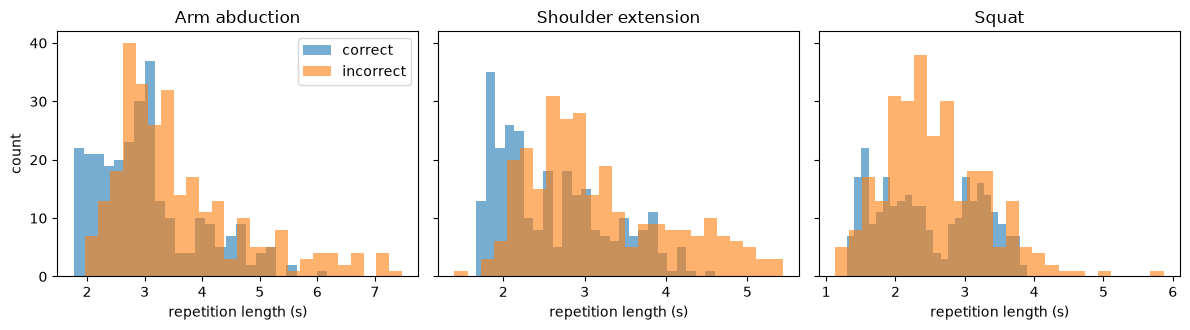

In [5]:
display(seg.groupby("exercise").n_frames.describe().round(1))
display(seg.groupby("label").n_frames.describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (ex, g) in zip(axes, seg.groupby("exercise")):
    for lab, gg in g.groupby("label"):
        ax.hist(gg.n_frames / 30, bins=25, alpha=0.6, label=lab)
    ax.set_title(ex); ax.set_xlabel("repetition length (s)")
axes[0].set_ylabel("count"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "fig_rep_length.png", dpi=150); plt.show()

## 5. Protocol structure

Each recording cycles through 11 participant orientations (0°–90° in 10° steps, plus 45°). Within each
orientation the participant performs a fixed script: 3 correct repetitions, then 5 incorrect ones (one per
error type for that exercise), then 2 correct. The labels are therefore block-structured, not random.

Block lengths: {10: 152, 11: 11, 12: 2}
Most common block pattern: {'cccXXXXXcc': 152, 'cccXXXXXXcc': 7, 'cccccXXXXXcc': 2}


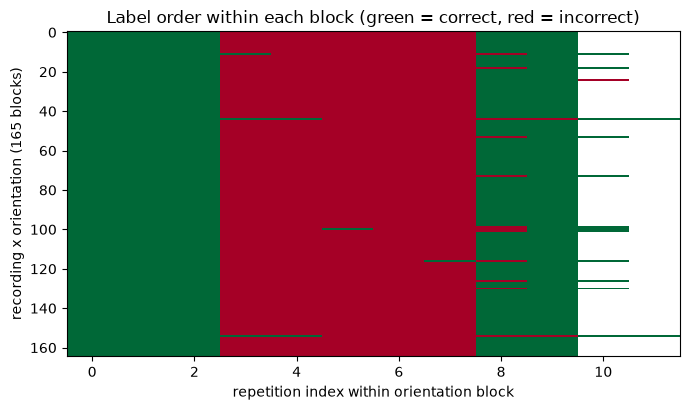

In [6]:
blocks = (seg.sort_values(["video_id", "person_orientation", "repetition_number"])
             .groupby(["video_id", "person_orientation"]).correctness_score.apply(list))
maxlen = blocks.map(len).max()
M = np.full((len(blocks), maxlen), np.nan)
for i, s in enumerate(blocks): M[i, :len(s)] = s
print("Block lengths:", pd.Series(blocks.map(len)).value_counts().to_dict())
print("Most common block pattern:", pd.Series(blocks.map(lambda s: "".join("c" if x == 1 else "X" for x in s))).value_counts().head(3).to_dict())

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.imshow(M, aspect="auto", cmap="RdYlGn_r", interpolation="nearest")
ax.set_xlabel("repetition index within orientation block"); ax.set_ylabel("recording x orientation (165 blocks)")
ax.set_title("Label order within each block (green = correct, red = incorrect)")
fig.tight_layout(); fig.savefig(FIG / "fig_block_structure.png", dpi=150); plt.show()

## 6. Pose files: integrity, alignment, visibility

For each of the 45 camera recordings there are two arrays of shape `(frames, 33, 4)`:
`_2d` holds image-normalised MediaPipe landmarks (x, y in [0, 1] of the frame, z relative) and `_3d` holds
MediaPipe world landmarks (metres, centred on the hips). The fourth channel is visibility in both.
The documentation warns that a skeleton sequence ends when the person leaves the frame, so sequences can
be shorter than their video.

In [7]:
def probe_frames(mp4):
    out = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0",
                          "-show_entries", "stream=nb_frames,width,height,r_frame_rate", "-of", "json", str(mp4)],
                         capture_output=True, text=True).stdout
    return json.loads(out)["streams"][0]

rows = []
for f in sorted(glob.glob(str(DATA / "mediapipe/*/*_3d.npy"))):
    name = Path(f).stem.replace("_3d", "")
    vid, cam = name.rsplit("_cam", 1); ex = vid.split("_")[0]
    a = np.load(f)
    a2 = np.load(f.replace("_3d", "_2d"))
    zero = np.abs(a[:, :, :3]).sum(axis=(1, 2)) == 0          # frames with no detected person
    reps = seg[seg.video_id == vid]
    in_rep = np.zeros(len(a), bool)
    for r in reps.itertuples(): in_rep[r.first_frame:min(r.last_frame + 1, len(a))] = True
    s = probe_frames(DATA / f"videos/{ex}/{name}.mp4")
    vis = a[~zero][:, :, 3]
    rows.append(dict(video_id=vid, cam=int(cam), skel_frames=len(a), video_frames=int(s["nb_frames"]),
                     res=f'{s["width"]}x{s["height"]}', fps=s["r_frame_rate"],
                     nan_2d=int(np.isnan(a2).sum()), nan_3d=int(np.isnan(a).sum()),
                     zero_frames=int(zero.sum()), zero_frames_in_reps=int((zero & in_rep).sum()),
                     last_labeled_frame=int(reps.last_frame.max()), reps_beyond_skeleton=int((reps.last_frame >= len(a)).sum()),
                     vis_mean=round(float(vis.mean()), 3), frac_vis_below_0_5=round(float((vis < 0.5).mean()), 3)))
integ = pd.DataFrame(rows)
display(integ)
print("Resolutions:", integ.res.unique(), "fps:", integ.fps.unique())
print("NaNs (2d, 3d):", integ.nan_2d.sum(), integ.nan_3d.sum())
print(f"Skeleton shorter than video: {(integ.skel_frames < integ.video_frames).sum()} / {len(integ)} recordings")
print("Labeled repetitions extending past the skeleton:", integ.reps_beyond_skeleton.sum())
print(f"No-detection (all-zero) frames: {integ.zero_frames.sum()} total, {integ.zero_frames_in_reps.sum()} inside labeled repetitions")

,video_id,cam,skel_frames,video_frames,res,fps,nan_2d,nan_3d,zero_frames,zero_frames_in_reps,last_labeled_frame,reps_beyond_skeleton,vis_mean,frac_vis_below_0_5
0,ex1_Honza,1,24388,24388,1080x1920,30/1,0,0,10,0,24230,0,0.930,0.049
1,ex1_Honza,2,24485,24634,1080x1920,30/1,0,0,0,0,24230,0,0.969,0.004
2,ex1_Honza,3,24374,24374,1080x1920,30/1,0,0,11,0,24230,0,0.903,0.074
3,ex1_Mima,1,13724,14027,1080x1920,30/1,0,0,0,0,13658,0,0.908,0.066
4,ex1_Mima,2,13783,13868,1080x1920,30/1,0,0,4,0,13658,0,0.961,0.009
5,ex1_Mima,3,13739,13772,1080x1920,30/1,0,0,0,0,13658,0,0.874,0.102
6,ex1_Petra,1,12900,12900,1080x1920,30/1,0,0,0,0,12837,0,0.911,0.068
7,ex1_Petra,2,12898,12898,1080x1920,30/1,0,0,0,0,12837,0,0.950,0.020
8,ex1_Petra,3,12900,12900,1080x1920,30/1,0,0,0,0,12837,0,0.879,0.096
9,ex1_Terka,1,15016,15149,1080x1920,30/1,0,0,0,0,14842,0,0.916,0.071


Resolutions: <StringArray>
['1080x1920']
Length: 1, dtype: str fps: <StringArray>
['30/1']
Length: 1, dtype: str
NaNs (2d, 3d): 0 0
Skeleton shorter than video: 29 / 45 recordings
Labeled repetitions extending past the skeleton: 0
No-detection (all-zero) frames: 1345 total, 0 inside labeled repetitions


,vis_mean,frac_vis_below_0_5,zero_frames
cam,,,
1,0.900,0.081,50.867
2,0.941,0.032,27.667
3,0.896,0.082,11.133


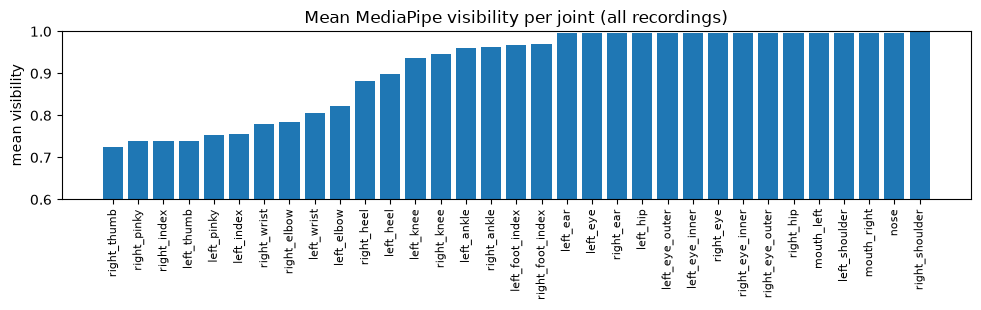

In [8]:
# Visibility per joint and per camera
all_vis = np.concatenate([np.load(f)[:, :, 3] for f in sorted(glob.glob(str(DATA / "mediapipe/*/*_3d.npy")))])
joint_vis = pd.Series(all_vis.mean(axis=0), index=joint_names).sort_values()
display(integ.groupby("cam")[["vis_mean", "frac_vis_below_0_5", "zero_frames"]].mean().round(3))

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(joint_vis.index, joint_vis.values); ax.set_ylabel("mean visibility"); ax.set_ylim(0.6, 1.0)
ax.tick_params(axis="x", rotation=90, labelsize=8); ax.set_title("Mean MediaPipe visibility per joint (all recordings)")
fig.tight_layout(); fig.savefig(FIG / "fig_joint_visibility.png", dpi=150); plt.show()

In [9]:
# What the 3d arrays contain: hip-centred world coordinates in metres
a3 = np.load(DATA / "mediapipe/ex1/ex1_Honza_cam1_3d.npy"); a2 = np.load(DATA / "mediapipe/ex1/ex1_Honza_cam1_2d.npy")
ok = np.abs(a3[:, :, :3]).sum(axis=(1, 2)) > 0
print("2d x/y/z range:", a2[ok][:, :, :3].min(axis=(0, 1)).round(2), a2[ok][:, :, :3].max(axis=(0, 1)).round(2))
print("3d x/y/z range:", a3[ok][:, :, :3].min(axis=(0, 1)).round(2), a3[ok][:, :, :3].max(axis=(0, 1)).round(2))
print("3d hip midpoint mean:", a3[ok][:, 23:25, :3].mean(axis=(0, 1)).round(4))
sw = np.linalg.norm(a3[ok][:, 11, :3] - a3[ok][:, 12, :3], axis=1)
print("3d shoulder width (m): median %.3f, 5th–95th pct %.3f–%.3f" % (np.median(sw), *np.percentile(sw, [5, 95])))

2d x/y/z range: [-0.15  0.22 -1.87] [1.13 1.67 2.32]
3d x/y/z range: [-0.72 -1.06 -0.48] [0.44 0.91 0.49]
3d hip midpoint mean: [-0.     -0.0002  0.0006]
3d shoulder width (m): median 0.319, 5th–95th pct 0.302–0.332


## 7. Representative examples

One correct and one incorrect (`ERR_BENT_ARM`) arm-abduction repetition from the same participant and
orientation, seen from all three cameras, with the 2d landmarks overlaid on the video frame at the top of
the movement.

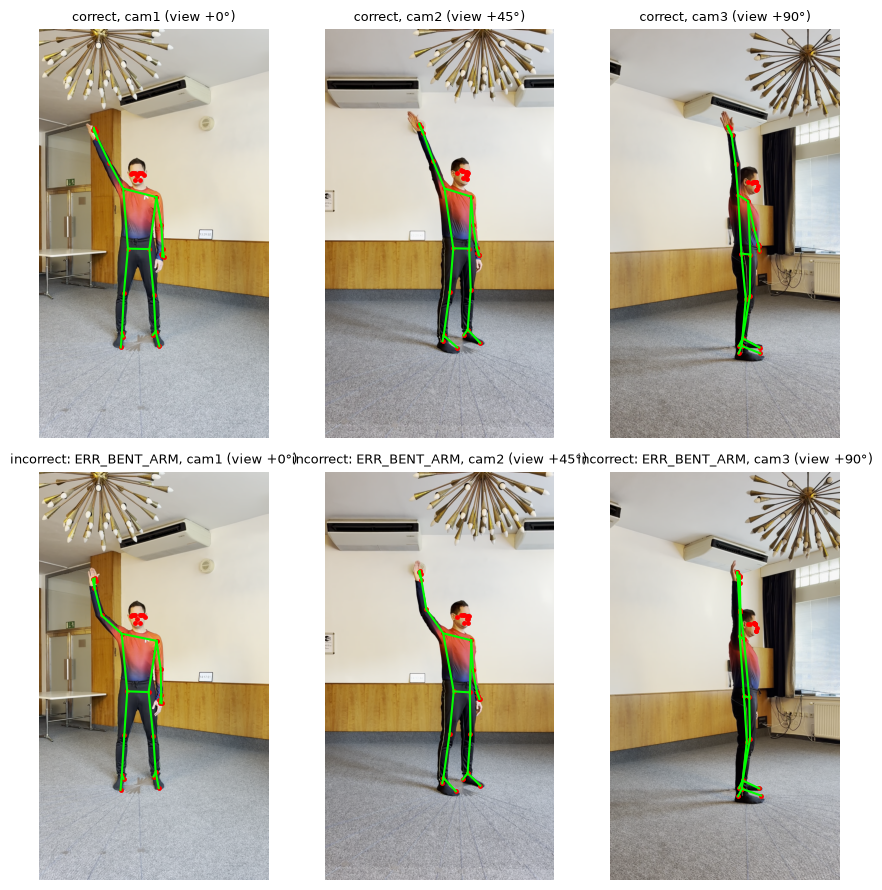

In [10]:
EDGES = [(11,12),(11,13),(13,15),(12,14),(14,16),(11,23),(12,24),(23,24),(23,25),(25,27),(24,26),(26,28),
         (15,17),(15,19),(16,18),(16,20),(27,29),(27,31),(28,30),(28,32)]

def grab_frame(mp4, frame, out):
    subprocess.run(["ffmpeg", "-y", "-v", "error", "-ss", f"{frame/30:.4f}", "-i", str(mp4),
                    "-frames:v", "1", "-update", "1", str(out)], check=True)
    return plt.imread(out)

def peak_frame(rep, cam):
    a2 = np.load(DATA / f"mediapipe/ex{rep.exercise_id}/{rep.video_id}_cam{cam}_2d.npy")
    seq = a2[rep.first_frame:rep.last_frame + 1]
    return rep.first_frame + int(np.argmin(seq[:, 16, 1]))   # right wrist highest in image (smallest y)

cand = seg[(seg.video_id == "ex1_Honza") & (seg.person_orientation == 0)]
rep_ok = cand[cand.label == "correct"].iloc[0]
rep_bad = cand[cand.error_description == "ERR_BENT_ARM"].iloc[0]

fig, axes = plt.subplots(2, 3, figsize=(9, 9))
for row, (rep, title) in enumerate([(rep_ok, "correct"), (rep_bad, "incorrect: ERR_BENT_ARM")]):
    for cam in (1, 2, 3):
        fr = peak_frame(rep, cam)
        img = grab_frame(DATA / f"videos/ex1/{rep.video_id}_cam{cam}.mp4", fr, FIG / "_tmp_frame.png")
        H, W = img.shape[:2]
        pts = np.load(DATA / f"mediapipe/ex1/{rep.video_id}_cam{cam}_2d.npy")[fr]
        ax = axes[row, cam - 1]; ax.imshow(img)
        for i, j in EDGES: ax.plot([pts[i,0]*W, pts[j,0]*W], [pts[i,1]*H, pts[j,1]*H], "-", color="lime", lw=1.5)
        ax.scatter(pts[:,0]*W, pts[:,1]*H, s=6, c="red")
        ax.set_title(f"{title}, cam{cam} (view {[0,45,90][cam-1] - rep.person_orientation:+d}°)", fontsize=9); ax.axis("off")
fig.tight_layout(); fig.savefig(FIG / "fig_examples.png", dpi=130); plt.show()
(FIG / "_tmp_frame.png").unlink(missing_ok=True)

### Joint angles separate error types

A first look at the biomechanical-feature hypothesis: the right elbow angle computed from the 3d world
landmarks over time-normalised repetitions, correct versus `ERR_BENT_ARM`, and the right knee angle for
correct squats versus `ERR_SHALLOW_SQUAT`.

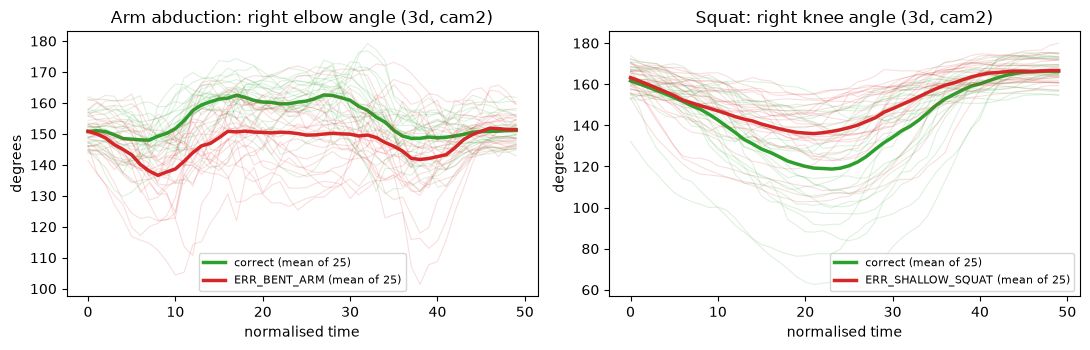

In [11]:
def angle(a, b, c):
    v1, v2 = a - b, c - b
    cos = (v1 * v2).sum(-1) / (np.linalg.norm(v1, axis=-1) * np.linalg.norm(v2, axis=-1) + 1e-9)
    return np.degrees(np.arccos(np.clip(cos, -1, 1)))

def angle_traces(rep_rows, joints, cam=2, n=50):
    out = []
    for r in rep_rows.itertuples():
        a3 = np.load(DATA / f"mediapipe/ex{r.exercise_id}/{r.video_id}_cam{cam}_3d.npy")[r.first_frame:r.last_frame + 1, :, :3]
        ang = angle(a3[:, joints[0]], a3[:, joints[1]], a3[:, joints[2]])
        out.append(np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(ang)), ang))
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (ex_id, err, joints, name) in zip(axes, [(1, "ERR_BENT_ARM", (12, 14, 16), "right elbow angle"),
                                                (6, "ERR_SHALLOW_SQUAT", (24, 26, 28), "right knee angle")]):
    sub = seg[seg.exercise_id == ex_id]
    for lab, sel, color in [("correct", sub[sub.label == "correct"].sample(25, random_state=0), "tab:green"),
                            (err, sub[sub.error_description == err].sample(25, random_state=0), "tab:red")]:
        T = angle_traces(sel, joints)
        ax.plot(T.T, color=color, alpha=0.15, lw=0.8)
        ax.plot(T.mean(0), color=color, lw=2.5, label=f"{lab} (mean of 25)")
    ax.set_title(f"{EX_NAME[ex_id]}: {name} (3d, cam2)"); ax.set_xlabel("normalised time"); ax.set_ylabel("degrees"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig_angle_traces.png", dpi=150); plt.show()

## 8. Summary of findings

- **Balance.** 832 correct vs 833 incorrect overall, and balanced within every exercise, participant, and
  orientation. No class-imbalance handling needed for the binary task. The incorrect class is heterogeneous:
  15 error types, roughly 55 repetitions each.
- **Protocol structure.** Labels follow a fixed script inside each orientation block (3 correct, 5 incorrect,
  2 correct). Incorrect repetitions are also longer on average. Both are data problems: splits must keep
  whole participants together, and features should be time-normalised so duration alone cannot act as a
  shortcut.
- **Missing values.** No NaNs in any array. 1,345 all-zero frames (person not detected) exist, but all lie
  outside labeled repetitions.
- **Alignment.** Skeleton sequences are shorter than their video in 29 of 45 recordings, as documented, but
  every labeled repetition is fully covered by its skeleton. The three cameras' sequences differ in length by
  up to a few hundred frames, so cross-camera alignment relies on the shared frame indices from the start.
- **Pose quality.** Visibility is lowest for hand, wrist and elbow joints and lowest overall for the
  exercising (right) arm, and the 45° camera (cam2) has the fewest low-visibility joints. Lower-body
  visibility is poor in some squat recordings.
- **Preprocessing needs.** Slice repetitions by frame index; resample to a fixed length; hip-centre and
  scale-normalise coordinates (3d arrays are already hip-centred, in metres); compute joint angles and
  velocities; carry visibility as a feature or mask.